# Hands-On Task — Association Rule Mining (Lecture 6)

**Course:** INFO 4670  
**Focus:** Support, Confidence, Apriori, FP-Growth  

Run cells top-to-bottom. Fill short answers where prompted.


Setup → Toy Data Preprocessing → Apriori → Association Rule Generation → FP-Growth → Real Data Preprocessing → Real Data Rule Generation → Visualization (Optional).

## 0) Setup
If a package is missing locally, uncomment the `%pip install` lines and run once.

In [14]:
import warnings

warnings.filterwarnings("ignore", category=DeprecationWarning)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [15]:
%pip install pandas mlxtend matplotlib networkx

In [16]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules


## 1) Load a Small Transaction Dataset (Toy)
We start with a tiny dataset to make outputs easy to read.

In [17]:
# Toy dataset with 5 transactions
transactions = [
    ["Milk", "Bread", "Butter"],
    ["Milk", "Bread"],
    ["Bread", "Butter"],
    ["Milk", "Bread", "Eggs"],
    ["Milk", "Eggs"]
]

pd.DataFrame({"TID": [f"T{i+1}" for i in range(len(transactions))],
              "Items": [", ".join(t) for t in transactions]})


,TID,Items
0,T1,"Milk, Bread, Butter"
1,T2,"Milk, Bread"
2,T3,"Bread, Butter"
3,T4,"Milk, Bread, Eggs"
4,T5,"Milk, Eggs"


**Q1.** How many transactions are there?  
Answer: `5`


## 2) Convert to One-Hot Encoding

In [18]:
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
oht = pd.DataFrame(te_ary, columns=te.columns_).astype(bool)
oht.head()


,Bread,Butter,Eggs,Milk
0,True,True,False,True
1,True,False,False,True
2,True,True,False,False
3,True,False,True,True
4,False,False,True,True


**Q2.** What does `True`/`1` mean in this matrix?  
Answer: `An item was purchased in that transaction`


## 3) Frequent Itemsets with Apriori (min_support = 0.4)

In [19]:
freq_ap = apriori(oht, min_support=0.4, use_colnames=True)
freq_ap.sort_values('support', ascending=False)


,support,itemsets
0,0.8,(Bread)
3,0.8,(Milk)
5,0.6,"(Milk, Bread)"
2,0.4,(Eggs)
1,0.4,(Butter)
4,0.4,"(Butter, Bread)"
6,0.4,"(Eggs, Milk)"


**Q3.** Write down the top 3 frequent itemsets from the table above.  
Answer: `Bread, Milk, [Bread, Milk]`


## 4) Association Rules (metric = confidence, min_threshold = 0.6)

In [20]:
rules_ap = association_rules(freq_ap, metric='confidence', min_threshold=0.6)
rules_ap[['antecedents','consequents','support','confidence','lift']].sort_values('confidence', ascending=False)


,antecedents,consequents,support,confidence,lift
0,(Butter),(Bread),0.4,1.00,1.2500
3,(Eggs),(Milk),0.4,1.00,1.2500
1,(Milk),(Bread),0.6,0.75,0.9375
2,(Bread),(Milk),0.6,0.75,0.9375


**Q4.** Pick one rule and explain in your own words (1–2 sentences).  
Example: `{Milk} ⇒ {Bread}` …  
Answer: `{Butter} ⇒ {Bread} is sitting at 1.00 confidence due to each time there was a transaction that butter was purchased, bread was also purchased. This occured in 40% of the transactions (support) and lift is at 1.25 due to the support for the rule being divided by the support for butter and bread multipled (0.4 / (0.4 * 0.8)).`


## 5) FP-Growth Comparison (min_support = 0.4)

In [21]:
freq_fp = fpgrowth(oht, min_support=0.4, use_colnames=True)
rules_fp = association_rules(freq_fp, metric='confidence', min_threshold=0.6)
rules_fp[['antecedents','consequents','support','confidence','lift']].sort_values('confidence', ascending=False)


,antecedents,consequents,support,confidence,lift
3,(Eggs),(Milk),0.4,1.00,1.2500
2,(Butter),(Bread),0.4,1.00,1.2500
1,(Bread),(Milk),0.6,0.75,0.9375
0,(Milk),(Bread),0.6,0.75,0.9375


**Q5.** Do Apriori and FP-Growth produce the same rules on this toy set? Why or why not?  
Answer: `Yes. Apriori relies on building candidate sets, but uses a technique of pruning any supersets if any of the subsets are infrequent enough (below the min_support). FP-Growth finds the same information through using a recursive tree system where the most frequent items are inserted at the top and then item sets are revealed when the tree branches via recursion with the next most frequent items in lower branches.`


## 6) Real Dataset Mini-Demo — `bread_basket.csv`
We will use only the **first 200 transactions** in class for speed. Place `bread_basket.csv` next to this notebook or edit the path.

In [22]:
CSV_PATH = "bread_basket-2.csv"  # update if needed
bread = pd.read_csv(CSV_PATH)

# Build a list of items per transaction (subset first N transactions)
N = 200
basket = (bread.groupby('transaction')['item'].apply(list)
                 .reset_index()
                 .sort_values('transaction')
                 .head(N)['item']
                 .tolist())

# One-hot encode
te_b = TransactionEncoder()
oht_b = pd.DataFrame(te_b.fit(basket).transform(basket), columns=te_b.columns_).astype(bool)
oht_b.shape


(200, 30)

In [23]:
# Frequent itemsets and rules (adjust thresholds to show a few rules)
minsup = 0.01   # 5%
minconf = 0.3   # 30%

freq_b = fpgrowth(oht_b, min_support=minsup, use_colnames=True)
rules_b = association_rules(freq_b, metric='confidence', min_threshold=minconf)
rules_b[['antecedents','consequents','support','confidence','lift']].sort_values(['lift','confidence'], ascending=False).head(15)


,antecedents,consequents,support,confidence,lift
19,(Mineral water),(Hearty & Seasonal),0.015,0.500000,9.090909
18,(Tartine),"(Tea, Coffee)",0.015,0.500000,7.692308
2,(Hot chocolate),(Cookies),0.010,0.400000,6.666667
29,(Frittata),(Hearty & Seasonal),0.010,0.333333,6.060606
35,(Soup),(Hearty & Seasonal),0.015,0.333333,6.060606
33,(Frittata),"(Tea, Coffee)",0.010,0.333333,5.128205
26,(Victorian Sponge),(Tea),0.015,0.750000,3.947368
17,"(Tartine, Coffee)",(Tea),0.015,0.600000,3.157895
24,"(Juice, Coffee)",(Pastry),0.010,0.333333,2.898551
8,(Medialuna),(Pastry),0.020,0.307692,2.675585


**Q6.** Pick one rule from the table above that you find interesting. Why?  
Answer: `{Hot chocolate} ⇒ {Cookies}, from eye scanning it appears neither item appears in any of the other itemsets that were gleaned with the above filters. I believe it is likely that both items have low support themselves, but combined frequently enough to get a satisfactory support and confidence. The lift value does indicate a strong association. This comes out of what I believe is just occuring twice in the dataset.`


## 7) (Optional) Visualize a Small Rule Subgraph
Filter to rules among `{Bread, Coffee, Cake, Tea}` and draw a small directed graph.

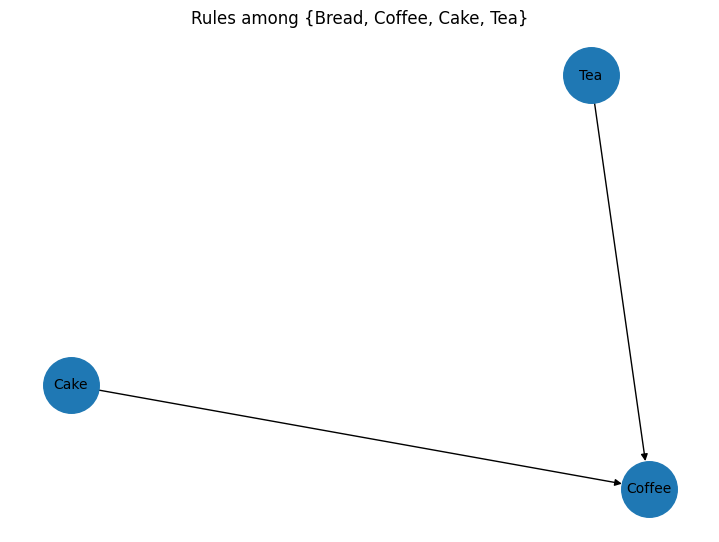

In [24]:
import networkx as nx

focus = {'Bread','Coffee','Cake','Tea'}
sub = rules_b[
    rules_b['antecedents'].apply(lambda s: s.issubset(focus)) &
    rules_b['consequents'].apply(lambda s: s.issubset(focus))
].copy()

G = nx.DiGraph()
for _, r in sub.iterrows():
    a = ','.join(sorted(list(r['antecedents'])))
    c = ','.join(sorted(list(r['consequents'])))
    G.add_edge(a, c, weight=float(r['confidence']), lift=float(r['lift']))

plt.figure(figsize=(7,5))
pos = nx.spring_layout(G, seed=0)
nx.draw(G, pos, with_labels=True, node_size=1600, font_size=10, arrows=True)
plt.title("Rules among {Bread, Coffee, Cake, Tea}")
plt.show()


## 8) Wrap-up
- Difference between **Apriori** and **FP-Growth** in one sentence:  
  Answer: `Apriori builds all of the itemset as candidates and rules them out through elimination based on frequency (while using some logic to eliminate large sets) while FP-Growth utilizes recursion starting at the most frequent items to make nodes which end up being prefixes for subsequent recursions going down a tree.`
- Why do we need **lift** in addition to support & confidence?  
  Answer: `Lift gives us a decent way to evalaute association strength between antecedents and consequents. It gives us a number that compares the support for the antecedents and consequents vs the support for antecdents or consequents.`
